# Community 1: Physics-informed KAN

**Disclaimer: This is uploaded from a github user, not the KAN authors. KAN authors did not writer this or proofread this carefully, hence are not responsible for mistakes in this notebook. If you have questions, please consult the github user who uploaded it. Thank you!**

Using device: cuda


Step: 199 | Loss: 0.011


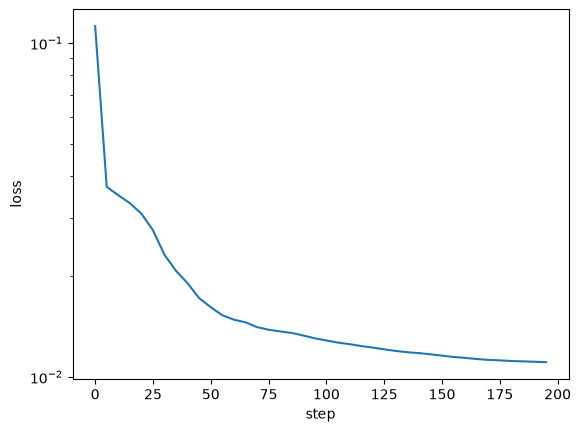

In [1]:
import torch
from torch import autograd
from tqdm import tqdm
import matplotlib.pyplot as plt
from xkan import KANNetwork
from xkan.train import LBFGS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

rho = torch.tensor(1.0, device=device, requires_grad=False)
nu = torch.tensor(0.01, device=device, requires_grad=False)
eps = torch.tensor(1e-8, device=device, requires_grad=False)

width, height = 10.0, 2.0
num_points_x, num_points_y = 100, 20

x = torch.linspace(0, width, num_points_x, device=device, requires_grad=False)
y = torch.linspace(0, height, num_points_y, device=device, requires_grad=False)
X, Y = torch.meshgrid(x, y, indexing='ij')
coordinates = torch.stack([X.flatten(), Y.flatten()], dim=1).to(device)
coordinates.requires_grad = True  # Ensure coordinates require grad

# noise_scale_base=0.25 of pykan 0.1 (base weights 1/sqrt(n_in) plus noise): scale_base_mu=1, scale_base_sigma=0.25
model = KANNetwork([2, 3, 3, 3], grid=5, k=10, grid_eps=1.0,
                   scale_base_mu=1.0, scale_base_sigma=0.25).to(device)

def batch_jacobian(func, x, create_graph=False):
    def _func_sum(x):
        return func(x).sum(dim=0)
    return autograd.functional.jacobian(_func_sum, x, create_graph=create_graph).permute(1, 0, 2)

def batch_hessian(func, x):
    jacobian = batch_jacobian(func, x, create_graph=True)
    hessians = []
    for i in range(jacobian.size(1)):
        grad = autograd.grad(jacobian[:, i].sum(), x, create_graph=True, retain_graph=True)[0]
        hessians.append(grad.unsqueeze(1))
    return torch.cat(hessians, dim=1)

def navier_stokes_residuals(coords):
    coords = coords.clone().detach().requires_grad_(True)  # Ensure coords require grad
    y_pred = model(coords)
    grads = batch_jacobian(model, coords, create_graph=True)
    hessians = batch_hessian(model, coords)

    u, v, p = y_pred[:, 0], y_pred[:, 1], y_pred[:, 2]
    u_x, u_y = grads[:, 0, 0], grads[:, 0, 1]
    v_x, v_y = grads[:, 1, 0], grads[:, 1, 1]
    p_x, p_y = grads[:, 2, 0], grads[:, 2, 1]

    u_xx, u_yy = hessians[:, 0, 0], hessians[:, 0, 1]
    v_xx, v_yy = hessians[:, 1, 0], hessians[:, 1, 1]

    continuity = u_x + v_y + eps * p
    x_momentum = u * u_x + v * u_y + (1 / rho) * p_x - nu * (u_xx + u_yy)
    y_momentum = u * v_x + v * v_y + (1 / rho) * p_y - nu * (v_xx + v_yy)

    no_slip_mask = (coords[:, 1] == 0) | (coords[:, 1] == height)
    inlet_mask = (coords[:, 0] == 0)
    outlet_mask = (coords[:, 0] == width)

    no_slip_loss = torch.mean(u[no_slip_mask] ** 2 + v[no_slip_mask] ** 2)
    inlet_loss = torch.mean((u[inlet_mask] - 1) ** 2)
    outlet_pressure_loss = torch.mean(p[outlet_mask] ** 2)

    bc_loss = no_slip_loss + inlet_loss + outlet_pressure_loss
    total_loss = torch.mean(continuity ** 2 + x_momentum ** 2 + y_momentum ** 2) + bc_loss
    return total_loss

losses = []  # the loss every 5 steps (the original logged it to TensorBoard)

def train():
    optimizer = LBFGS(model.parameters(), lr=1,
                      history_size=10, line_search_fn="strong_wolfe", tolerance_grad=1e-32, tolerance_change=1e-32, tolerance_ys=1e-32)
    
    steps = 200 # 20 steps are enough
    pbar = tqdm(range(steps), desc='Training Progress')

    for step in pbar:
        def closure():
            optimizer.zero_grad()
            loss = navier_stokes_residuals(coordinates)
            loss.backward()
            return loss

        optimizer.step(closure)
        if step % 5 == 0:
            current_loss = closure().item()
            pbar.set_description("Step: %d | Loss: %.3f" %
                                 (step, current_loss))
            losses.append(current_loss)
    print("Step: %d | Loss: %.3f" % (step, current_loss))

train()

plt.semilogy(range(0, 5 * len(losses), 5), losses)
plt.xlabel('step')
plt.ylabel('loss');

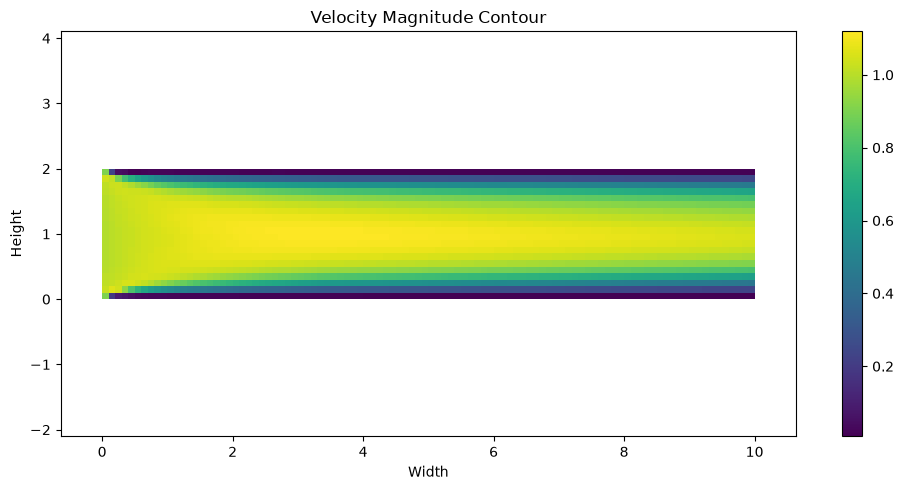

In [2]:
u_pred = model(coordinates)[:, 0].detach().cpu().reshape(
    num_points_x, num_points_y).T

v_pred = model(coordinates)[:, 1].detach().cpu().reshape(
    num_points_x, num_points_y).T


magnitude = torch.sqrt(u_pred ** 2 + v_pred ** 2)

plt.figure(figsize=(10, 5))  # Set the figure size as needed
plt.imshow(magnitude, extent=(0, width, 0, height), origin='lower', cmap='viridis')
plt.colorbar()  # Add a colorbar to show the magnitude scale
plt.title('Velocity Magnitude Contour')
plt.xlabel('Width')
plt.ylabel('Height')
plt.axis('equal')  # Ensure the plot has equal scaling
plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

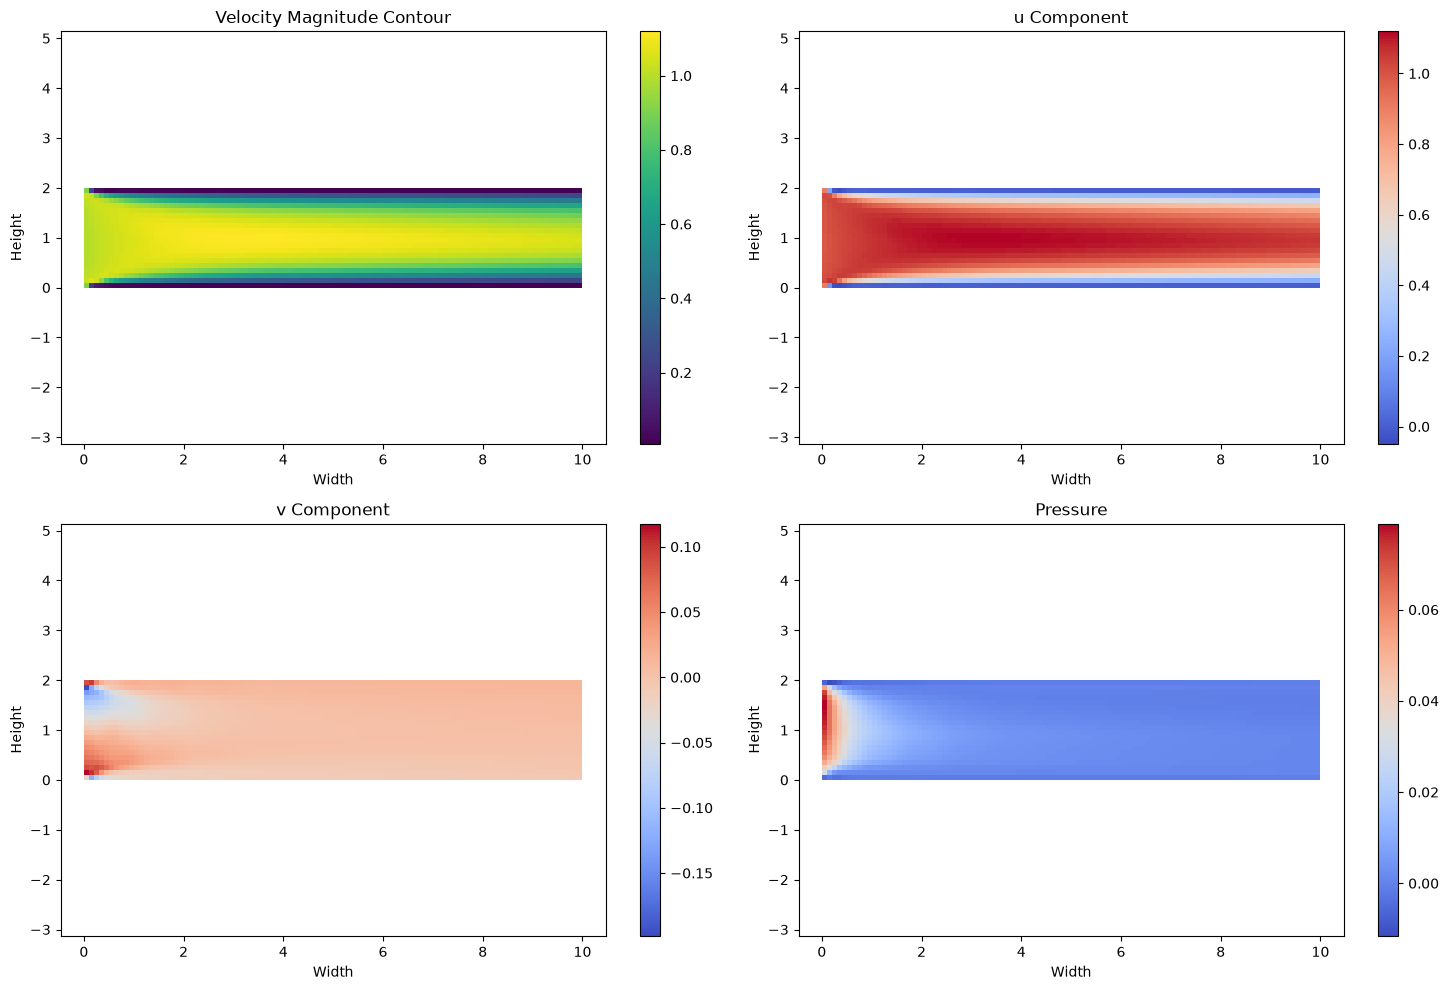

In [3]:
# Extracting predictions
u_pred = model(coordinates)[:, 0].detach().cpu().reshape(num_points_x, num_points_y).T
v_pred = model(coordinates)[:, 1].detach().cpu().reshape(num_points_x, num_points_y).T
p_pred = model(coordinates)[:, 2].detach().cpu().reshape(num_points_x, num_points_y).T

# Velocity Magnitude
magnitude = torch.sqrt(u_pred ** 2 + v_pred ** 2)

# Plotting all subplots
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

# Velocity Magnitude
im0 = axs[0, 0].imshow(magnitude, extent=(0, width, 0, height), origin='lower', cmap='viridis')
fig.colorbar(im0, ax=axs[0, 0])
axs[0, 0].set_title('Velocity Magnitude Contour')
axs[0, 0].set_xlabel('Width')
axs[0, 0].set_ylabel('Height')
axs[0, 0].axis('equal')

# u Component
im1 = axs[0, 1].imshow(u_pred, extent=(0, width, 0, height), origin='lower', cmap='coolwarm')
fig.colorbar(im1, ax=axs[0, 1])
axs[0, 1].set_title('u Component')
axs[0, 1].set_xlabel('Width')
axs[0, 1].set_ylabel('Height')
axs[0, 1].axis('equal')

# v Component
im2 = axs[1, 0].imshow(v_pred, extent=(0, width, 0, height), origin='lower', cmap='coolwarm')
fig.colorbar(im2, ax=axs[1, 0])
axs[1, 0].set_title('v Component')
axs[1, 0].set_xlabel('Width')
axs[1, 0].set_ylabel('Height')
axs[1, 0].axis('equal')

# Pressure
im3 = axs[1, 1].imshow(p_pred, extent=(0, width, 0, height), origin='lower', cmap='coolwarm')
fig.colorbar(im3, ax=axs[1, 1])
axs[1, 1].set_title('Pressure')
axs[1, 1].set_xlabel('Width')
axs[1, 1].set_ylabel('Height')
axs[1, 1].axis('equal')

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

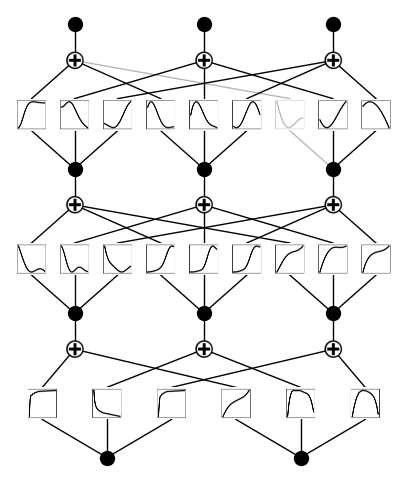

In [4]:
from xkan.viz import plot
plot(model, coordinates, beta=10);